# AISE 4010 — Deep Learning for Time Series
## Group 4 — Stage 1 Demo

**Dataset:** Open Power System Data (OPSD), hourly time-series package  
**Source:** https://data.open-power-system-data.org/time_series/  
**Target:** `DE_load_actual_entsoe_transparency` — Germany total electricity load (MW)  
**Task:** Use the previous **168 hours (7 days)** of load to predict Germany's load **24 hours ahead**.  
**Native frequency:** 1 hour  
**Resampling rule:** None — the supplied 60-minute file is already at the required hourly frequency.  
**Missing-value rule:** No imputer is fitted; the single missing target occurs at the first timestamp and is dropped because there is no earlier observation available for causal imputation.

### Stage 1 scope
1. Data audit and exploratory analysis  
2. Chronological train / validation / test split  
3. Training-only standardization  
4. Daily and weekly naive baselines  
5. MLP  
6. 1D CNN  
7. Small validation-only grid search  
8. Final controlled comparison  
9. Conclusion and unresolved risk

> Important: all model selection and hyperparameter tuning uses the validation set. The test set is evaluated only after the configuration is fixed.


## 0. Imports and reproducibility

Run this notebook in **Google Colab** if TensorFlow is not installed locally.


In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Flatten, Conv1D, MaxPooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 137
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


TensorFlow: 2.21.0
Seed: 137


## 1. Load the OPSD data

The project uses the hourly single-index OPSD CSV.  
If the file is not already in Colab, upload `time_series_60min_singleindex.csv` when prompted.


In [2]:
CSV_FILE = "time_series_60min_singleindex.csv"
TARGET = "DE_load_actual_entsoe_transparency"

if not os.path.exists(CSV_FILE):
    try:
        from google.colab import files
        print("Upload time_series_60min_singleindex.csv")
        files.upload()
    except Exception:
        raise FileNotFoundError(
            "Place time_series_60min_singleindex.csv in the notebook folder."
        )

df = pd.read_csv(
    CSV_FILE,
    usecols=["utc_timestamp", TARGET],
    parse_dates=["utc_timestamp"]
).sort_values("utc_timestamp").reset_index(drop=True)

print("Raw shape:", df.shape)
display(df.head())


Upload time_series_60min_singleindex.csv


Saving time_series_60min_singleindex.csv to time_series_60min_singleindex.csv
Raw shape: (50401, 2)


,utc_timestamp,DE_load_actual_entsoe_transparency
0,2014-12-31 23:00:00+00:00,NaN
1,2015-01-01 00:00:00+00:00,41151.0
2,2015-01-01 01:00:00+00:00,40135.0
3,2015-01-01 02:00:00+00:00,39106.0
4,2015-01-01 03:00:00+00:00,38765.0


## 2. Data audit

For the demo, we need to explicitly show:
- source and target;
- unit and native frequency;
- coverage;
- missing values;
- duplicate timestamps;
- timestamp gaps.

The OPSD documentation defines the selected target as **Germany total load in MW**.


In [3]:
timestamp_duplicates = int(df["utc_timestamp"].duplicated().sum())

time_diffs = df["utc_timestamp"].diff().dropna()
non_hourly_steps = int((time_diffs != pd.Timedelta(hours=1)).sum())

audit = pd.DataFrame({
    "Item": [
        "Dataset source",
        "Target",
        "Unit",
        "Native frequency",
        "Resampling rule",
        "Rows before cleaning",
        "Start timestamp",
        "End timestamp",
        "Duplicate timestamps",
        "Non-hourly timestamp gaps",
        "Missing target values",
        "Imputation / missing-value handling"
    ],
    "Value": [
        "https://data.open-power-system-data.org/time_series/",
        TARGET,
        "MW",
        "1 hour",
        "None — using native 60-minute data",
        len(df),
        str(df["utc_timestamp"].min()),
        str(df["utc_timestamp"].max()),
        timestamp_duplicates,
        non_hourly_steps,
        int(df[TARGET].isna().sum()),
        "No imputer fitted; drop the single missing first target value"
    ]
})

display(audit)


,Item,Value
0,Dataset source,https://data.open-power-system-data.org/time_s...
1,Target,DE_load_actual_entsoe_transparency
2,Unit,MW
3,Native frequency,1 hour
4,Resampling rule,None — using native 60-minute data
5,Rows before cleaning,50401
6,Start timestamp,2014-12-31 23:00:00+00:00
7,End timestamp,2020-09-30 23:00:00+00:00
8,Duplicate timestamps,0
9,Non-hourly timestamp gaps,0


In [4]:
# The target has one missing value at the first timestamp.
# Dropping it is safe because there is no earlier value available to impute it from.
data = df.dropna(subset=[TARGET]).copy().reset_index(drop=True)

print("Clean shape:", data.shape)
print("Clean coverage:", data["utc_timestamp"].min(), "to", data["utc_timestamp"].max())
print("\nTarget summary (MW):")
display(data[TARGET].describe().to_frame().T)


Clean shape: (50400, 2)
Clean coverage: 2015-01-01 00:00:00+00:00 to 2020-09-30 23:00:00+00:00

Target summary (MW):


,count,mean,std,min,25%,50%,75%,max
DE_load_actual_entsoe_transparency,50400.0,55492.468552,10015.431042,31307.0,47106.0,55092.0,64309.25,77549.0


## 3. Exploratory analysis

### Figure 1 — Full Germany load series


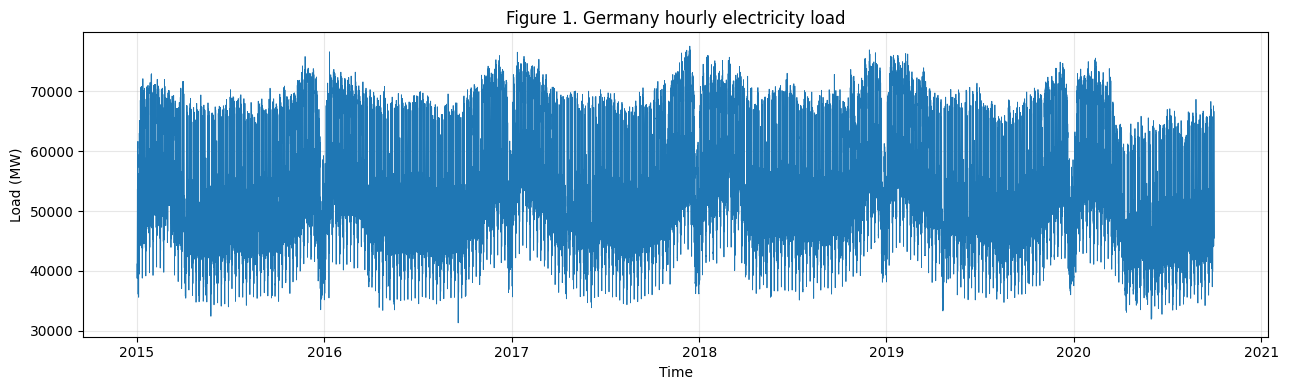

In [5]:
plt.figure(figsize=(13, 4))
plt.plot(data["utc_timestamp"], data[TARGET], linewidth=0.6)
plt.title("Figure 1. Germany hourly electricity load")
plt.xlabel("Time")
plt.ylabel("Load (MW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Figure 2 — Average load by hour of day

This shows the recurring daily demand pattern.


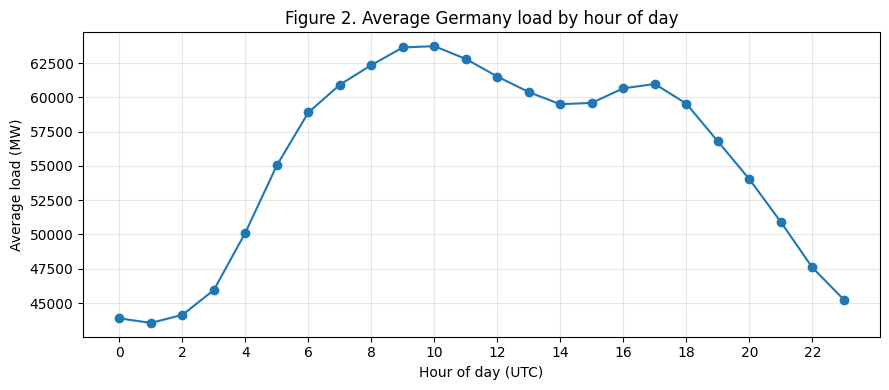

In [6]:
eda = data.copy()
eda["hour"] = eda["utc_timestamp"].dt.hour

hourly_profile = eda.groupby("hour")[TARGET].mean()

plt.figure(figsize=(9, 4))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Figure 2. Average Germany load by hour of day")
plt.xlabel("Hour of day (UTC)")
plt.ylabel("Average load (MW)")
plt.xticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Forecasting contract

We lock these choices **before modelling**:

- **Target:** Germany electricity load (MW)
- **Lookback:** 168 hours = 7 days
- **Forecast horizon:** 24 hours ahead
- **Split:** 60% train / 20% validation / 20% test, in chronological order
- **Scaling:** mean and standard deviation calculated from the training period only
- **Metrics:** MAE and RMSE
- **Fair comparison:** all models use the same windows, target, split and metrics


In [7]:
LOOKBACK = 168
HORIZON = 24

values = data[TARGET].to_numpy(dtype=np.float32)
timestamps = data["utc_timestamp"].to_numpy()

n = len(values)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

split_table = pd.DataFrame([
    {
        "Split": "Train",
        "Raw rows": train_end,
        "Start": data["utc_timestamp"].iloc[0],
        "End": data["utc_timestamp"].iloc[train_end - 1]
    },
    {
        "Split": "Validation",
        "Raw rows": val_end - train_end,
        "Start": data["utc_timestamp"].iloc[train_end],
        "End": data["utc_timestamp"].iloc[val_end - 1]
    },
    {
        "Split": "Test",
        "Raw rows": n - val_end,
        "Start": data["utc_timestamp"].iloc[val_end],
        "End": data["utc_timestamp"].iloc[-1]
    }
])

display(split_table)


,Split,Raw rows,Start,End
0,Train,30240,2015-01-01 00:00:00+00:00,2018-06-13 23:00:00+00:00
1,Validation,10080,2018-06-14 00:00:00+00:00,2019-08-07 23:00:00+00:00
2,Test,10080,2019-08-08 00:00:00+00:00,2020-09-30 23:00:00+00:00


### Chronological split diagram

The order is never shuffled:

**Oldest data → Train (60%) → Validation (20%) → Test (20%) → Newest data**


## 5. Leakage-safe standardization and window creation

The scaler uses **training values only**.  
A window contains 168 past hourly load values and predicts the value 24 hours ahead.


In [8]:
train_mean = float(values[:train_end].mean())
train_std = float(values[:train_end].std())

values_scaled = (values - train_mean) / train_std

print(f"Training mean: {train_mean:.3f} MW")
print(f"Training std:  {train_std:.3f} MW")


Training mean: 55740.730 MW
Training std:  10063.438 MW


In [9]:
def make_windows(scaled_values, original_values, lookback, horizon):
    X, y_scaled, y_original, target_indices = [], [], [], []

    for t in range(lookback, len(scaled_values) - horizon + 1):
        target_index = t + horizon - 1

        X.append(scaled_values[t-lookback:t])
        y_scaled.append(scaled_values[target_index])
        y_original.append(original_values[target_index])
        target_indices.append(target_index)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y_scaled, dtype=np.float32),
        np.asarray(y_original, dtype=np.float32),
        np.asarray(target_indices)
    )

X_all, y_all_scaled, y_all_mw, target_idx = make_windows(
    values_scaled,
    values,
    LOOKBACK,
    HORIZON
)

train_mask = target_idx < train_end
val_mask = (target_idx >= train_end) & (target_idx < val_end)
test_mask = target_idx >= val_end

X_train = X_all[train_mask]
y_train = y_all_scaled[train_mask]
y_train_mw = y_all_mw[train_mask]

X_val = X_all[val_mask]
y_val = y_all_scaled[val_mask]
y_val_mw = y_all_mw[val_mask]

X_test = X_all[test_mask]
y_test = y_all_scaled[test_mask]
y_test_mw = y_all_mw[test_mask]

# CNN needs a channel dimension.
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

window_shapes = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "X shape (MLP)": [str(X_train.shape), str(X_val.shape), str(X_test.shape)],
    "X shape (CNN)": [str(X_train_cnn.shape), str(X_val_cnn.shape), str(X_test_cnn.shape)],
    "y shape": [str(y_train.shape), str(y_val.shape), str(y_test.shape)]
})

display(window_shapes)


,Split,X shape (MLP),X shape (CNN),y shape
0,Train,"(30049, 168)","(30049, 168, 1)","(30049,)"
1,Validation,"(10080, 168)","(10080, 168, 1)","(10080,)"
2,Test,"(10080, 168)","(10080, 168, 1)","(10080,)"


## 6. Traditional baselines

We use two simple non-neural forecasting rules:

1. **Daily persistence:** use the last observed value as the 24-hour-ahead prediction.
2. **Weekly seasonal naive:** use the load from the same hour one week earlier.

The weekly baseline is especially important because electricity demand often has a weekly cycle.


In [10]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5
    }

# For this 24-hour horizon, the last point in the 168-hour input window
# is the load exactly 24 hours before the target.
daily_pred_all = X_all[:, -1] * train_std + train_mean

# Same hour one week before the target.
weekly_pred_all = values[target_idx - 168]

baseline_rows = []

for split_name, mask, y_true in [
    ("Validation", val_mask, y_val_mw),
    ("Test", test_mask, y_test_mw)
]:
    for model_name, pred_all in [
        ("Daily persistence", daily_pred_all),
        ("Weekly seasonal naive", weekly_pred_all)
    ]:
        m = regression_metrics(y_true, pred_all[mask])
        baseline_rows.append({
            "Split": split_name,
            "Model": model_name,
            "MAE_MW": m["MAE"],
            "RMSE_MW": m["RMSE"]
        })

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(2))


,Split,Model,MAE_MW,RMSE_MW
0,Validation,Daily persistence,4618.69,7024.07
1,Validation,Weekly seasonal naive,2386.61,4191.50
2,Test,Daily persistence,4125.03,6308.97
3,Test,Weekly seasonal naive,2267.75,3886.99


## 7. Neural-network helpers

Both neural networks predict the same scaled target and are evaluated in MW after inverse scaling.


### Fair-comparison contract
- MLP and CNN receive the same **168 historical load values** (CNN only adds a channel dimension).
- Both predict the same **24-hour-ahead target**.
- Both use **MSE training loss**.
- Both are evaluated on the exact same validation/test target instances using **MAE and RMSE**.
- Baselines use the same target times and forecasting horizon.
- Hyperparameters are selected from validation results only.


In [11]:
def inverse_target(z):
    return np.asarray(z).reshape(-1) * train_std + train_mean

def build_mlp(hidden_units=64, learning_rate=0.001):
    model = Sequential([
        Input(shape=(LOOKBACK,)),
        Dense(hidden_units, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1)
    ])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse"
    )
    return model

def build_cnn(filters=32, kernel_size=5, learning_rate=0.001):
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            padding="same",
            activation="relu"
        ),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(32, activation="relu"),
        Dense(1)
    ])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse"
    )
    return model

def fit_and_score(model, Xtr, ytr, Xv, yv, yv_mw, epochs=12):
    callback = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    start = time.perf_counter()

    history = model.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=epochs,
        batch_size=128,
        shuffle=False,
        callbacks=[callback],
        verbose=0
    )

    train_seconds = time.perf_counter() - start

    pred_scaled = model.predict(Xv, verbose=0).reshape(-1)
    pred_mw = inverse_target(pred_scaled)
    metrics = regression_metrics(yv_mw, pred_mw)

    return {
        "model": model,
        "history": history,
        "MAE_MW": metrics["MAE"],
        "RMSE_MW": metrics["RMSE"],
        "params": model.count_params(),
        "train_seconds": train_seconds,
        "epochs_ran": len(history.history["loss"])
    }


## 8. Default MLP


In [12]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

mlp = build_mlp(hidden_units=64, learning_rate=0.001)
mlp_result = fit_and_score(
    mlp,
    X_train, y_train,
    X_val, y_val, y_val_mw
)

print("MLP validation MAE (MW):", round(mlp_result["MAE_MW"], 2))
print("MLP validation RMSE (MW):", round(mlp_result["RMSE_MW"], 2))
print("MLP parameters:", mlp_result["params"])
print("MLP training time (s):", round(mlp_result["train_seconds"], 2))
print("Epochs run:", mlp_result["epochs_ran"])


# Save trained weights before later TensorFlow session resets.
mlp_default_weights = mlp_result["model"].get_weights()


MLP validation MAE (MW): 2625.98
MLP validation RMSE (MW): 3587.54
MLP parameters: 12929
MLP training time (s): 12.14
Epochs run: 12


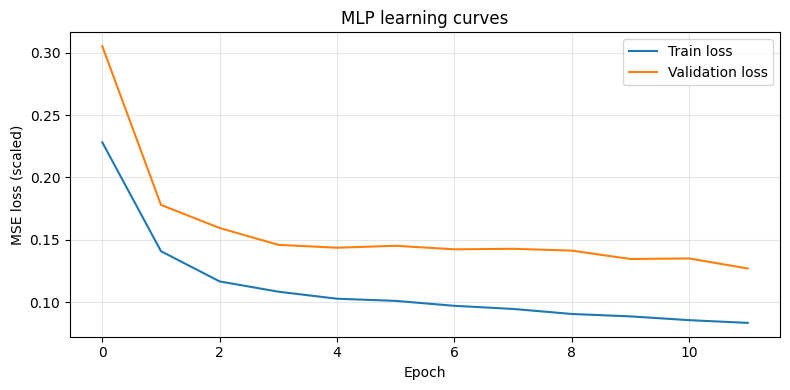

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(mlp_result["history"].history["loss"], label="Train loss")
plt.plot(mlp_result["history"].history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (scaled)")
plt.title("MLP learning curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Default 1D CNN


In [14]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

cnn = build_cnn(filters=32, kernel_size=5, learning_rate=0.001)
cnn_result = fit_and_score(
    cnn,
    X_train_cnn, y_train,
    X_val_cnn, y_val, y_val_mw
)

print("CNN validation MAE (MW):", round(cnn_result["MAE_MW"], 2))
print("CNN validation RMSE (MW):", round(cnn_result["RMSE_MW"], 2))
print("CNN parameters:", cnn_result["params"])
print("CNN training time (s):", round(cnn_result["train_seconds"], 2))
print("Epochs run:", cnn_result["epochs_ran"])


# Save trained weights before later TensorFlow session resets.
cnn_default_weights = cnn_result["model"].get_weights()


CNN validation MAE (MW): 2441.63
CNN validation RMSE (MW): 3341.53
CNN parameters: 86273
CNN training time (s): 57.62
Epochs run: 12


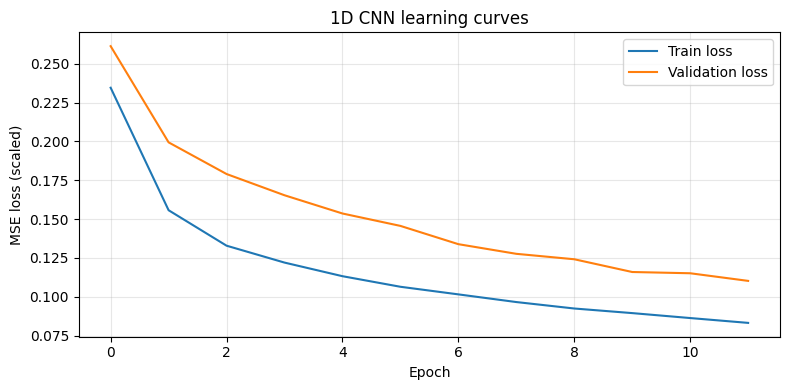

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(cnn_result["history"].history["loss"], label="Train loss")
plt.plot(cnn_result["history"].history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (scaled)")
plt.title("1D CNN learning curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Validation comparison before HPO

The model with the lower validation RMSE is the architecture we tune.


In [16]:
pre_hpo = pd.DataFrame([
    {
        "Model": "MLP",
        "Validation_MAE_MW": mlp_result["MAE_MW"],
        "Validation_RMSE_MW": mlp_result["RMSE_MW"],
        "Parameters": mlp_result["params"],
        "Training_seconds": mlp_result["train_seconds"]
    },
    {
        "Model": "1D CNN",
        "Validation_MAE_MW": cnn_result["MAE_MW"],
        "Validation_RMSE_MW": cnn_result["RMSE_MW"],
        "Parameters": cnn_result["params"],
        "Training_seconds": cnn_result["train_seconds"]
    }
]).sort_values("Validation_RMSE_MW").reset_index(drop=True)

display(pre_hpo.round(2))

architecture_to_tune = pre_hpo.iloc[0]["Model"]
print("Architecture selected for grid search:", architecture_to_tune)


,Model,Validation_MAE_MW,Validation_RMSE_MW,Parameters,Training_seconds
0,1D CNN,2441.63,3341.53,86273,57.62
1,MLP,2625.98,3587.54,12929,12.14


Architecture selected for grid search: 1D CNN


## 11. Small validation-only grid search

The search budget is deliberately small for the Stage 1 checkpoint: **4 configurations**.

- If MLP wins the initial validation comparison: tune hidden units and learning rate.
- If CNN wins: tune filters and kernel size.

**Objective:** lowest validation RMSE in MW.  
The test set is not used for HPO.


In [17]:
hpo_rows = []

if architecture_to_tune == "MLP":
    search_space = [
        {"hidden_units": 32, "learning_rate": 0.001},
        {"hidden_units": 32, "learning_rate": 0.0005},
        {"hidden_units": 64, "learning_rate": 0.001},
        {"hidden_units": 64, "learning_rate": 0.0005},
    ]

    for config in search_space:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        candidate = build_mlp(**config)
        result = fit_and_score(
            candidate,
            X_train, y_train,
            X_val, y_val, y_val_mw,
            epochs=10
        )

        hpo_rows.append({
            "Architecture": "MLP",
            **config,
            "filters": np.nan,
            "kernel_size": np.nan,
            "Validation_MAE_MW": result["MAE_MW"],
            "Validation_RMSE_MW": result["RMSE_MW"],
            "Parameters": result["params"],
            "Training_seconds": result["train_seconds"]
        })

else:
    search_space = [
        {"filters": 16, "kernel_size": 3},
        {"filters": 16, "kernel_size": 7},
        {"filters": 32, "kernel_size": 3},
        {"filters": 32, "kernel_size": 7},
    ]

    for config in search_space:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        candidate = build_cnn(**config, learning_rate=0.001)
        result = fit_and_score(
            candidate,
            X_train_cnn, y_train,
            X_val_cnn, y_val, y_val_mw,
            epochs=10
        )

        hpo_rows.append({
            "Architecture": "1D CNN",
            "hidden_units": np.nan,
            "learning_rate": 0.001,
            **config,
            "Validation_MAE_MW": result["MAE_MW"],
            "Validation_RMSE_MW": result["RMSE_MW"],
            "Parameters": result["params"],
            "Training_seconds": result["train_seconds"]
        })

hpo_results = pd.DataFrame(hpo_rows).sort_values(
    "Validation_RMSE_MW"
).reset_index(drop=True)

display(hpo_results.round(3))

best_hpo = hpo_results.iloc[0]
print("\nSelected configuration:")
display(best_hpo.to_frame().T)


,Architecture,hidden_units,learning_rate,filters,kernel_size,Validation_MAE_MW,Validation_RMSE_MW,Parameters,Training_seconds
0,1D CNN,NaN,0.001,16,7,2405.573,3323.509,43201,38.042
1,1D CNN,NaN,0.001,32,3,2508.480,3451.277,86209,46.656
2,1D CNN,NaN,0.001,16,3,2699.722,3594.964,43137,36.725
3,1D CNN,NaN,0.001,32,7,2721.425,3659.862,86337,58.411



Selected configuration:


,Architecture,hidden_units,learning_rate,filters,kernel_size,Validation_MAE_MW,Validation_RMSE_MW,Parameters,Training_seconds
0,1D CNN,NaN,0.001,16,7,2405.573242,3323.509139,43201,38.041596


## 12. Retrain the selected HPO configuration

We rebuild the selected configuration with the same training/validation protocol.  
After this cell, the configuration is locked.


In [18]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

if best_hpo["Architecture"] == "MLP":
    best_model_name = "Tuned MLP"
    best_model = build_mlp(
        hidden_units=int(best_hpo["hidden_units"]),
        learning_rate=float(best_hpo["learning_rate"])
    )
    best_result = fit_and_score(
        best_model,
        X_train, y_train,
        X_val, y_val, y_val_mw,
        epochs=12
    )
    best_test_X = X_test

else:
    best_model_name = "Tuned 1D CNN"
    best_model = build_cnn(
        filters=int(best_hpo["filters"]),
        kernel_size=int(best_hpo["kernel_size"]),
        learning_rate=float(best_hpo["learning_rate"])
    )
    best_result = fit_and_score(
        best_model,
        X_train_cnn, y_train,
        X_val_cnn, y_val, y_val_mw,
        epochs=12
    )
    best_test_X = X_test_cnn

print("Locked model:", best_model_name)
print("Validation RMSE (MW):", round(best_result["RMSE_MW"], 2))


Locked model: Tuned 1D CNN
Validation RMSE (MW): 3209.77


## 13. Stage 1 test comparison

At this point model selection is finished.  
We now evaluate the fixed models on the Stage 1 test block and **do not change hyperparameters based on these results**.


In [19]:
def test_model(model, X, y_true_mw):
    start = time.perf_counter()
    pred_scaled = model.predict(X, verbose=0).reshape(-1)
    inference_seconds = time.perf_counter() - start

    pred_mw = inverse_target(pred_scaled)
    m = regression_metrics(y_true_mw, pred_mw)

    return {
        "MAE_MW": m["MAE"],
        "RMSE_MW": m["RMSE"],
        "Inference_ms_per_sample": 1000 * inference_seconds / len(X)
    }

# Rebuild the default models and restore their saved training weights.
# This makes the final comparison robust to clear_session() calls used during HPO.
mlp_for_test = build_mlp(hidden_units=64, learning_rate=0.001)
mlp_for_test.set_weights(mlp_default_weights)

cnn_for_test = build_cnn(filters=32, kernel_size=5, learning_rate=0.001)
cnn_for_test.set_weights(cnn_default_weights)

mlp_test = test_model(mlp_for_test, X_test, y_test_mw)
cnn_test = test_model(cnn_for_test, X_test_cnn, y_test_mw)
tuned_test = test_model(best_result["model"], best_test_X, y_test_mw)

test_baselines = baseline_results[baseline_results["Split"] == "Test"].copy()
best_baseline_rmse = float(test_baselines["RMSE_MW"].min())
best_baseline_name = test_baselines.loc[
    test_baselines["RMSE_MW"].idxmin(), "Model"
]

comparison_rows = []

for _, row in test_baselines.iterrows():
    comparison_rows.append({
        "Model": row["Model"],
        "MAE_MW": row["MAE_MW"],
        "RMSE_MW": row["RMSE_MW"],
        "Parameters": 0,
        "Training_seconds": 0.0,
        "Inference_ms_per_sample": 0.0,
        "Improvement_vs_best_baseline_%":
            100 * (best_baseline_rmse - row["RMSE_MW"]) / best_baseline_rmse
    })

for name, result, train_info in [
    ("MLP", mlp_test, mlp_result),
    ("1D CNN", cnn_test, cnn_result),
    (best_model_name, tuned_test, best_result)
]:
    comparison_rows.append({
        "Model": name,
        "MAE_MW": result["MAE_MW"],
        "RMSE_MW": result["RMSE_MW"],
        "Parameters": train_info["params"],
        "Training_seconds": train_info["train_seconds"],
        "Inference_ms_per_sample": result["Inference_ms_per_sample"],
        "Improvement_vs_best_baseline_%":
            100 * (best_baseline_rmse - result["RMSE_MW"]) / best_baseline_rmse
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    "RMSE_MW"
).reset_index(drop=True)

print("Best simple baseline:", best_baseline_name)
display(comparison.round(2))


Best simple baseline: Weekly seasonal naive


,Model,MAE_MW,RMSE_MW,Parameters,Training_seconds,Inference_ms_per_sample,Improvement_vs_best_baseline_%
0,Tuned 1D CNN,2266.02,3145.41,43201,47.04,0.08,19.08
1,1D CNN,2390.40,3240.42,86273,57.62,0.10,16.63
2,MLP,2533.88,3465.70,12929,12.14,0.06,10.84
3,Weekly seasonal naive,2267.75,3886.99,0,0.00,0.00,0.00
4,Daily persistence,4125.03,6308.97,0,0.00,0.00,-62.31


In [20]:
# Automatic Stage 1 conclusion from the final comparison table.
winner = comparison.iloc[0]
baseline_row = comparison[comparison["Model"] == best_baseline_name].iloc[0]

print(
    f"Concrete conclusion: {winner['Model']} achieved the lowest Stage 1 test RMSE "
    f"at {winner['RMSE_MW']:.2f} MW. The strongest simple baseline was "
    f"{best_baseline_name} at {baseline_row['RMSE_MW']:.2f} MW."
)

if winner["Model"] != best_baseline_name:
    improvement = 100 * (
        baseline_row["RMSE_MW"] - winner["RMSE_MW"]
    ) / baseline_row["RMSE_MW"]
    print(f"Improvement over the strongest simple baseline: {improvement:.2f}%")
else:
    print(
        "The neural models did not beat the strongest simple baseline at this checkpoint. "
        "That is still an important result because the comparison was performed under the same protocol."
    )

print(
    "Unresolved risk: the current models use historical load only. "
    "Weather, holidays and other demand drivers are not represented yet."
)


Concrete conclusion: Tuned 1D CNN achieved the lowest Stage 1 test RMSE at 3145.41 MW. The strongest simple baseline was Weekly seasonal naive at 3886.99 MW.
Improvement over the strongest simple baseline: 19.08%
Unresolved risk: the current models use historical load only. Weather, holidays and other demand drivers are not represented yet.


## 14. Example test predictions


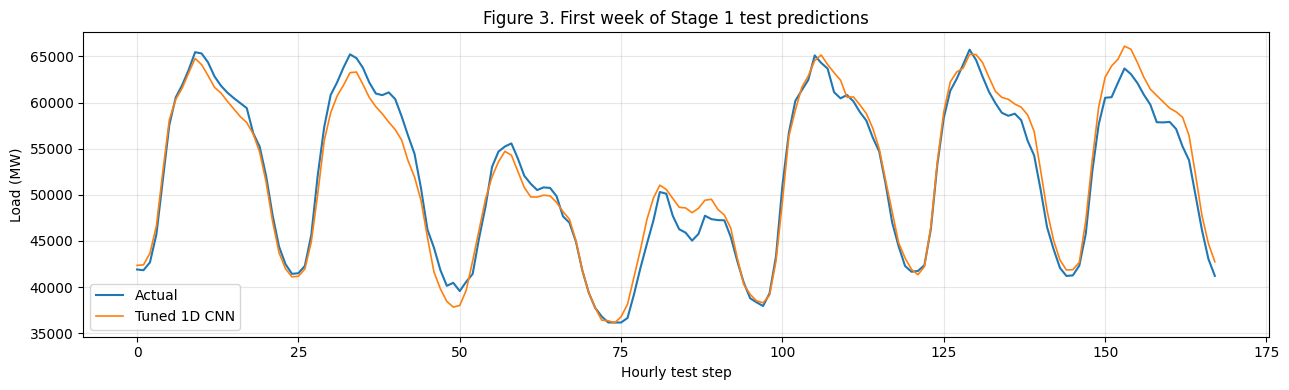

In [21]:
pred_best_scaled = best_result["model"].predict(best_test_X, verbose=0).reshape(-1)
pred_best_mw = inverse_target(pred_best_scaled)

n_show = 7 * 24  # one week

plt.figure(figsize=(13, 4))
plt.plot(y_test_mw[:n_show], label="Actual", linewidth=1.5)
plt.plot(pred_best_mw[:n_show], label=best_model_name, linewidth=1.2)
plt.title("Figure 3. First week of Stage 1 test predictions")
plt.xlabel("Hourly test step")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 15. Stage 1 conclusion and unresolved risk

### Concrete conclusion
Use the final comparison table above to state which method achieved the lowest RMSE and whether it improved over the strongest simple baseline.

A safe demo sentence is:

> “Under the same 168-hour input window and 24-hour forecasting horizon, the best Stage 1 model was **[read the top row of the comparison table]**. Its test RMSE was **[read value] MW**, compared with **[read value] MW** for the strongest simple baseline.”

### Unresolved risk
This Stage 1 model is intentionally **univariate**: it only uses historical electricity load. It does not yet use calendar effects, holidays, weather, or other exogenous drivers. This may hurt performance during unusual demand periods.

### Next stage
Keep the same forecasting protocol and add recurrent models (RNN/LSTM/GRU) and TCN, then compare them under the same split, windows and metrics.


## 16. Reproducibility / demo checkpoint

Before the live demo:

- Restart runtime and **Run all**.
- Keep all outputs visible.
- Push this notebook to GitHub.
- Paste the commit hash below.
- Do not change hyperparameters after seeing the test results.

**GitHub commit hash:** `PASTE_COMMIT_HASH_HERE`


In [22]:
# Lightweight smoke test for the live demo.
print("Target:", TARGET)
print("Lookback:", LOOKBACK, "hours")
print("Horizon:", HORIZON, "hours")
print("Train / Val / Test windows:", len(X_train), len(X_val), len(X_test))
print("No NaNs in model inputs:",
      not np.isnan(X_train).any(),
      not np.isnan(X_val).any(),
      not np.isnan(X_test).any())

assert X_train.shape[1] == LOOKBACK
assert X_train_cnn.shape[2] == 1
assert len(X_test) == len(y_test_mw)

print("Smoke test passed.")


Target: DE_load_actual_entsoe_transparency
Lookback: 168 hours
Horizon: 24 hours
Train / Val / Test windows: 30049 10080 10080
No NaNs in model inputs: True True True
Smoke test passed.


## Stage 1 rubric checklist

| Stage 1 requirement | Evidence in this notebook |
|---|---|
| Dataset source, target, unit, frequency, resampling | Sections 1–2 audit table |
| Coverage, gaps, duplicates, missingness | Section 2 audit table |
| At least two EDA figures | Figures 1–2 (plus test prediction figure) |
| Chronological split diagram/table | Section 4 split table + diagram |
| Scaler and imputer handling | Section 5 training-only standardization; Section 2 states no imputer is fitted and why |
| Explicit window shapes | Section 5 `window_shapes` table |
| Non-neural baseline | Section 6 daily persistence + weekly seasonal naive |
| MLP and CNN under controlled protocol | Sections 7–10 |
| Metrics, parameters, training time, baseline improvement | Section 13 comparison table |
| Grid-search configuration and results | Section 11 HPO table |
| Concrete conclusion + unresolved risk | Automatic conclusion + Section 15 |
| Live explanation | 60-second demo script at the end |


# 60-second live demo script

1. **Problem:** “I forecast Germany's hourly electricity load from Open Power System Data.”
2. **Target/unit:** “The target is actual German load in MW.”
3. **Audit:** “The hourly timestamps are continuous with no duplicates; the target has one missing value at the first row, which I drop.”
4. **Forecast setup:** “I use the previous 168 hours to predict 24 hours ahead.”
5. **Split:** “The split is chronological 60/20/20, and scaling statistics come from training data only.”
6. **Baselines:** “I compare against daily persistence and a weekly seasonal naive baseline.”
7. **Fair comparison:** “MLP and CNN use the same windows, horizon, target and metrics.”
8. **HPO:** “I choose the architecture using validation RMSE, then search four configurations using validation only.”
9. **Test:** “Only after the configuration is fixed do I evaluate the Stage 1 test block.”
10. **Risk:** “The current model is univariate, so weather, holidays and other drivers are not represented yet.”
